# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Sissi Wang, Alex Tan, Sadat Hassan]

**Date:** [11/03/2026]

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

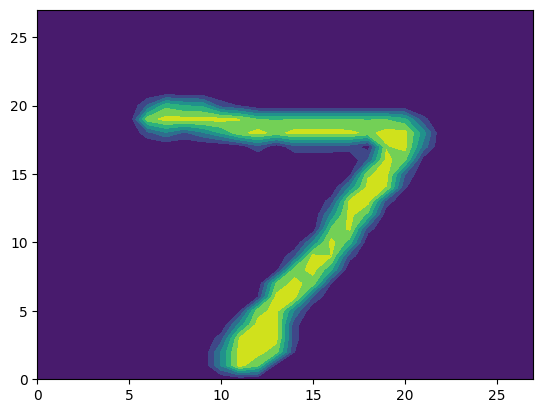

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

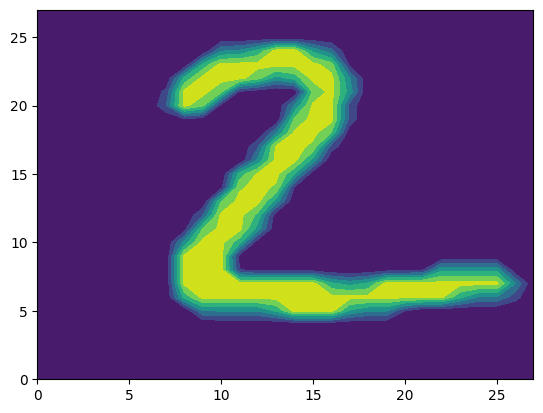

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

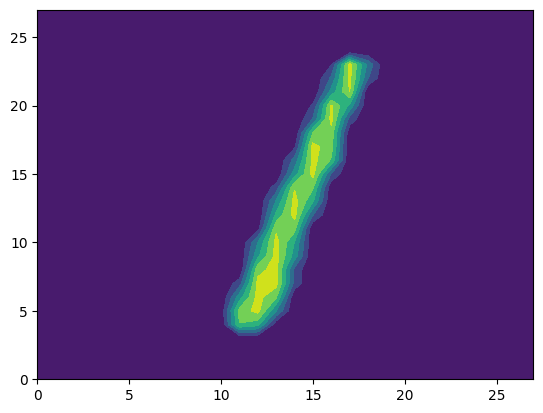

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

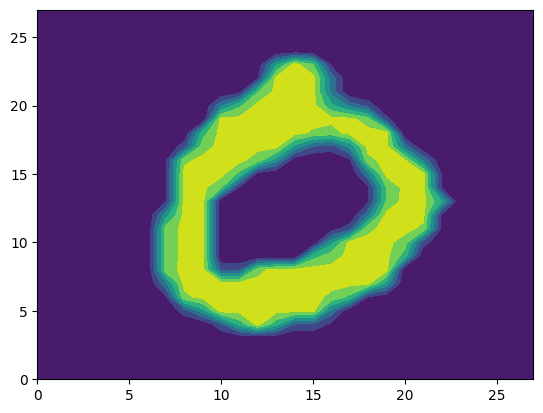

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

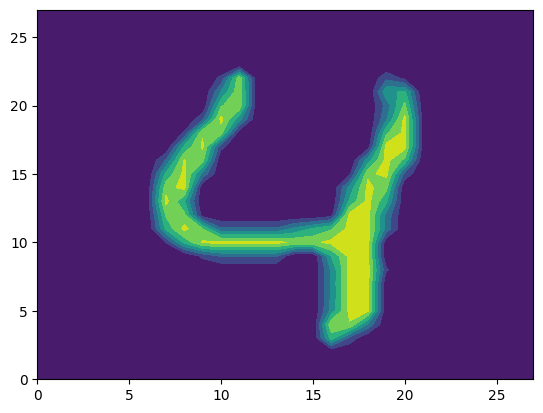

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
y_train shape: (60000,)
y_test shape: (10000,)
Reshaped train has zeros in first row: True
Reshaped test has zeros in first row: True
Reshaped train: (60000, 784)
Reshaped test: (10000, 784)


In [2]:
# Your Phase 1 solution to the problem goes here.
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

# Step 2
# What is the shape of X_train and X_test?
# What is the shape of X_train[i] and X_test[i] for each index i?
# What is the shape of y_train and y_test?
print("X_train shape:", X_train.shape) # 60000 images in X train and each image is stored in 2D grid as 28 rows and columns
print("X_test shape:", X_test.shape) # 10000 images in X test and each image is stored in 2D grid as 28 rows and columns
print("X_train[i] shape:", X_train[0].shape) # Shape of a single training image, 28 rows x 28 columns
print("X_test[i] shape:", X_test[0].shape) # Shape of a single testing image, 28 rows x 28 columns
print("y_train shape:", y_train.shape) # 60000 labels for the actual classification of each image in the X_train data
print("y_test shape:", y_test.shape) # 10000 labels for the actual classification of each image in the X_test data

# step 3
#Use Numpy's .reshape() method to covert the training and testing data from a matrix into an vector of features.
# So, X_test[index].reshape((1,784)) will convert the  index -th element of X_test into a  28×28=784 -length row vector of values, rather than a matrix.
# Turn X_train into an  N×784  matrix  X  that is suitable for scikit-learn's kNN classifier where  N  is the number of observations and  784=28∗28
# (you could use, for example, a for loop).

N_X_train = len(X_train)

X_train_reshaped = X_train.reshape((N_X_train,784))

N_X_test = len(X_test)

X_test_reshaped = X_test.reshape((N_X_test,784))

print("Reshaped train has zeros in first row:", X_train_reshaped[0].any())
print("Reshaped test has zeros in first row:", X_test_reshaped[0].any())
print("Reshaped train:", X_train_reshaped.shape)
print("Reshaped test:", X_test_reshaped.shape)


k = 1 Accuracy = 0.9704166666666667
k = 2 Accuracy = 0.9615
k = 3 Accuracy = 0.9703333333333334
k = 4 Accuracy = 0.9673333333333334
k = 5 Accuracy = 0.9675
k = 6 Accuracy = 0.9673333333333334
k = 7 Accuracy = 0.9663333333333334
k = 8 Accuracy = 0.9658333333333333
k = 9 Accuracy = 0.9654166666666667
k = 10 Accuracy = 0.9643333333333334
k = 11 Accuracy = 0.9641666666666666
k = 12 Accuracy = 0.9635
k = 13 Accuracy = 0.96325
k = 14 Accuracy = 0.9611666666666666
k = 15 Accuracy = 0.9619166666666666

Best k-value: 1 

Highest accuracy: 0.9704166666666667 



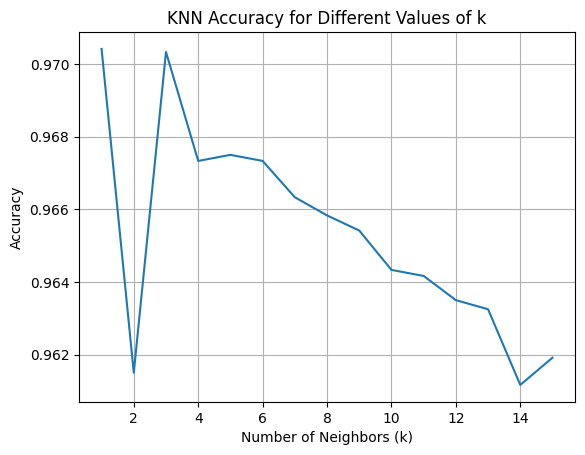

In [3]:
# Step 4 selecting best K
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_train_val, X_val, y_train_val, y_val = train_test_split(
    X_train_reshaped,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# find best k value based off of accuracy
k_values = range(1, 16)
accuracies = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_train_val, y_train_val)

  y_pred = knn.predict(X_val)
  accuracy = accuracy_score(y_val, y_pred)
  accuracies.append(accuracy)

  print("k =", k, "Accuracy =", accuracy)

k_star = int(k_values[np.argmax(accuracies)])
print("\nBest k-value:", k_star, "\n")
print("Highest accuracy:", max(accuracies), "\n")

# visualize k values
import matplotlib.pyplot as plt

plt.plot(k_values, accuracies)
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different Values of k")
plt.grid()
plt.show()


In [4]:
# Train the model based on optimal k
knn = KNeighborsClassifier(n_neighbors=k_star, n_jobs=-1)
knn.fit(X_train_reshaped, y_train)
y_pred = knn.predict(X_test_reshaped)

In [ ]:
# Step 5
# For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy,
# compute a confusion matrix, and explain your findings.
from sklearn.metrics import confusion_matrix, accuracy_score
print("\n--- Confusion Matrix ---")
# y_pred? or other variable? <----------------------------------
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\n--- Accuracy ---")
print(accuracy_score(y_test, y_pred))
print("96.9% accuracy is achieved from this. The most correctly guessed number was 1. \n"
"However, looking at the other bits of data, it is seen that some numbers that look similar to others naturally were\n"
"wrongly predicted in some cases. For example, 14 '7's and 10 '7's were wrongly predicted as 1 and 9 respesctively.\n"
"The highest number of misprediction was a 4 being mistaken as a 9 a total of 22 times. These numbers visually have\n"
"similarities, and this is very well the reason for these errors. Several incorrect predictions wer made, however,\n"
"there are immensely more correct predictons compared to incorrect ones.")

# Step 6
# For your confusion matrix, which mistakes are most likely?
# Do you find any interesting patterns?
print("The individual mistakes that were most likely are confusing a 4 for a 9 which occured 22 times, \n"
"3 being confused as a 5 a total of 19 times, and a 2 being confused as an 8 a total of 16 times. Generally speaking, \n"
"The number 5 gets mistaken the most as its accuracy is the lowest at 860 correct predictions whereas 1 gets mistaken the least at 1129 \n"
"correct predictions. The patterns appear to follow the visual similarities that the numbers have to each other. This can \n"
"directly be seen with the individual cases where in real life 4 can often be mistaken as a 9 and vice versa, similar to 1 and 7.")
# Step 7
# So, this is how computers "see." They convert an image into a matrix of values,
# that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data.
# To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data.
# (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

print ("To represent a color photo in matrix form, we can use a three-dimensional grid where each pixel holds three values for the RGB values \n"
"instead of a single grayscale number. This makes the matrix shape Height times Width times 3, with each pixel entry containing three numbers \n"
"from 0 to 255. To convert this into tabular data, we can flatten the 3D matrix into a single long 1D vector. \n"
"For example, a 100 by 100 pixel color photo becomes a row of 30,000 features by multiplying 100 times 100 times 3. \n"
"Finally, we repeat this flattening process for every photo in the dataset and stack the rows together. \n"
"This creates a standard tabular dataset where each row represents one photo.")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [0554cf68987996b2e29b1ee8a4d532d791090e4c]
- **AI tool and model used:** [Chat GPT-6]

### *Prompts used

1. [[Datasheet and notebook attached]The assignment directions is in the notebook, I have completed the steps for phase 1, please give bullet point suggestions to make my code better or better completing the assignment]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Your assignment says to visualize the first ten digits, but your loop only displays five.
2. These two lines are unnecessary. The .any() method returns True if at least one value is nonzero. It does not tell you whether the reshaping was done correctly.
3. Your answer is correct and follows the assignment directions. You correctly explain that a color image can be represented as a three-dimensional array containing RGB values. One small improvement: make it clear that each pixel contains three separate values, one for red, one for green, and one for blue.
4. Your confusion matrix and accuracy calculations are correct. However, after correcting Step 4, you should retrain your model using the entire training dataset and the optimal value of \(k\).

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Even though this is given code, AI pointed out the difference between the assignment directions and the resulting code. The given code only visualized 5 instead of 10 numbers. |
| 2 | Accept | The output of the .any() was not needed for the purpose of the assignment, it was used during writing the code to make sure results were right. |
| 3 | reject | Already stated that each pixel contains three separate values, asking for redundant correction. |
| 4 | reject | I already retrain the model on all the trainaing data, not just the training part from the train test split, misunderstood my code. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

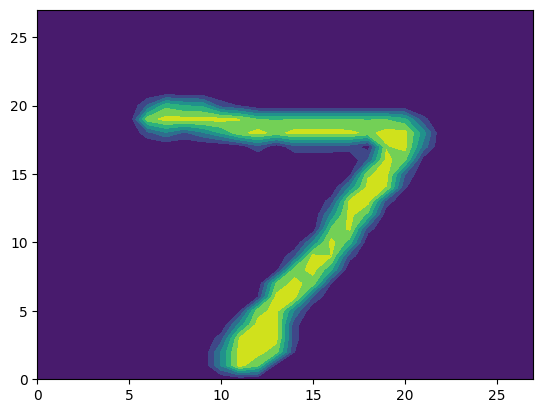

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

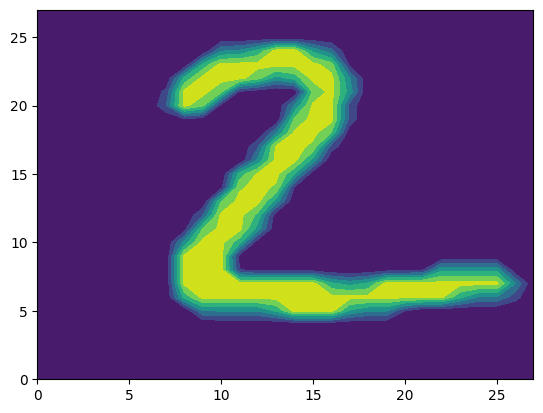

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

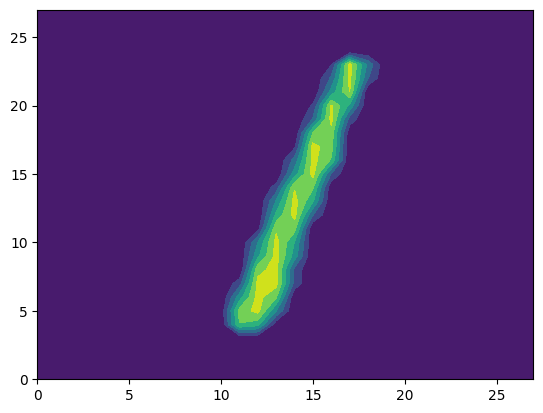

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

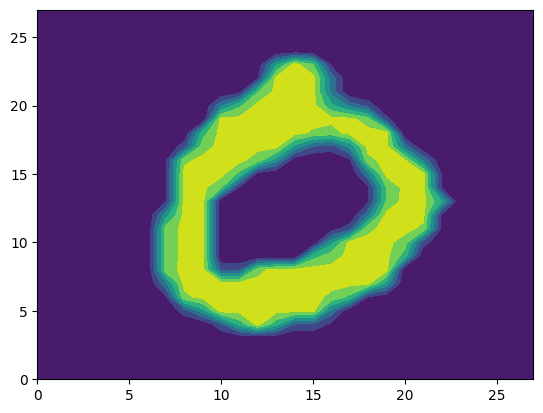

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

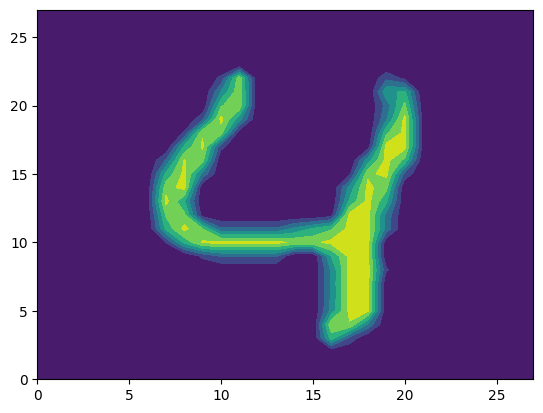

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  77 254 107   3   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  19 227 254 254   9   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  81 254 254 165   1   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   7 203 254 254  7

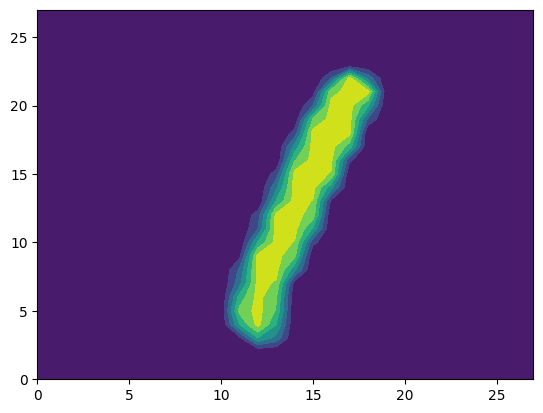

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  22 192 134  32   0   0   0   0   0   0   0   0  15  77   5   0   0   0   0]
 [  0   0   0   0   0   0   0   0  17 235 250 169   0   0   0   0   0   0   0   0  15 220 241  37   0   0   0   0]
 [  0   0   0   0   0   0   0  20 189 253 147   0   0   0   0   0   0   0   0   0 139 253 100   0   0   0   0   0]
 [  0   0   0   0   0   0   0  70 253 253  21   0   0   0   0   0   0   0   

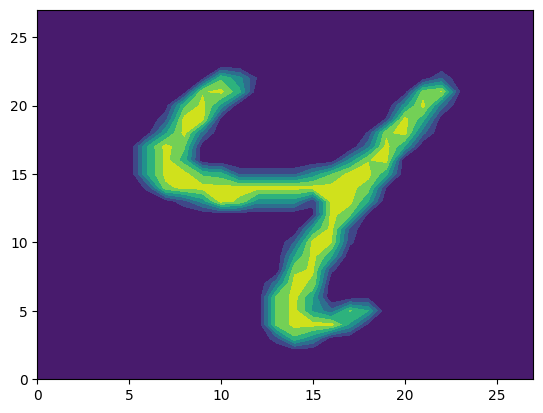

9 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  14 149 193   5   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  91 224 253 253  19   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  28 235 254 253 253 166  18   0   0   

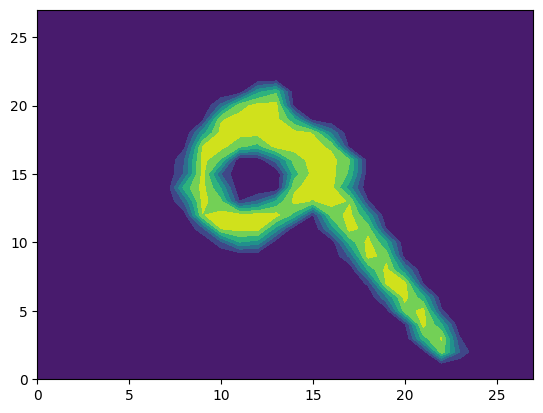

5 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  17  47  47  47  16 129  85  47   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  75 153 217 253 253 253 215 246 253 253   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  35 142 244 252 253 253 253 253 253 253 253 253 253   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  63 253 253 253 253 253 253 253 213 170 170 170 170   0   0   0]
 [  0   0   0   0   0   0   0   0  20 132  72   0  57 238 227 238 168 124  6

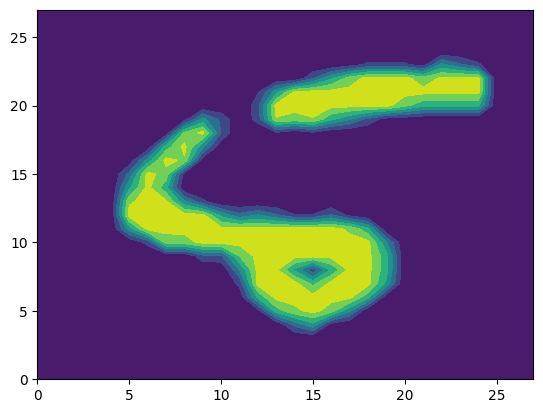

9 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  36  56 137 201 199  95  37   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  45 152 234 254 254 254 254 25

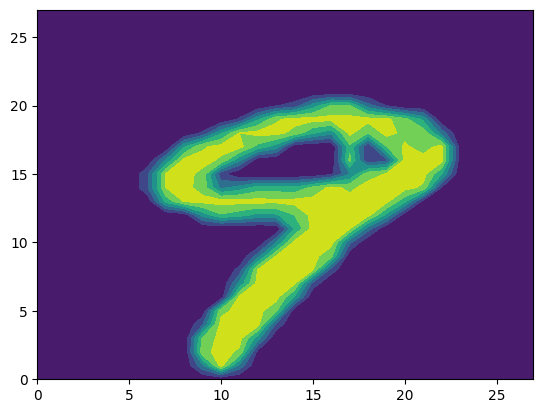

X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
X_train[i] shape: (28, 28)
X_test[i] shape: (28, 28)
y_train shape: (60000,)
y_test shape: (10000,)
Reshaped train: (60000, 784)
Reshaped test: (10000, 784)
k = 1 Accuracy = 0.9704166666666667
k = 2 Accuracy = 0.9615
k = 3 Accuracy = 0.9703333333333334
k = 4 Accuracy = 0.9673333333333334
k = 5 Accuracy = 0.9675
k = 6 Accuracy = 0.9673333333333334
k = 7 Accuracy = 0.9663333333333334
k = 8 Accuracy = 0.9658333333333333
k = 9 Accuracy = 0.9654166666666667
k = 10 Accuracy = 0.9643333333333334
k = 11 Accuracy = 0.9641666666666666
k = 12 Accuracy = 0.9635
k = 13 Accuracy = 0.96325
k = 14 Accuracy = 0.9611666666666666
k = 15 Accuracy = 0.9619166666666666

Best k-value: 1 

Highest accuracy: 0.9704166666666667 



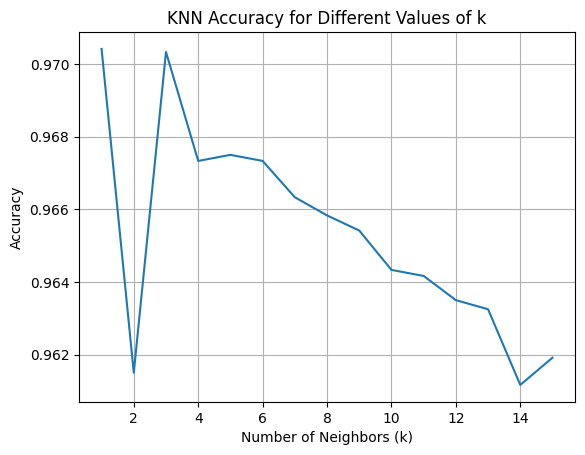


--- Confusion Matrix ---
[[ 973    1    1    0    0    1    3    1    0    0]
 [   0 1129    3    0    1    1    1    0    0    0]
 [   7    6  992    5    1    0    2   16    3    0]
 [   0    1    2  970    1   19    0    7    7    3]
 [   0    7    0    0  944    0    3    5    1   22]
 [   1    1    0   12    2  860    5    1    6    4]
 [   4    2    0    0    3    5  944    0    0    0]
 [   0   14    6    2    4    0    0  992    0   10]
 [   6    1    3   14    5   13    3    4  920    5]
 [   2    5    1    6   10    5    1   11    1  967]]

--- Accuracy ---
0.9691
96.9% accuracy is achieved from this. The most correctly guessed number was 1. 
However, looking at the other bits of data, it is seen that some numbers that look similar to others naturally were
wrongly predicted in some cases. For example, 14 '7's and 10 '7's were wrongly predicted as 1 and 9 respesctively.
The highest number of misprediction was a 4 being mistaken as a 9 a total of 22 times. These numbers visual

In [6]:
# Your Phase 2 solution to the problem goes here.
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(10): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

# Step 2
# What is the shape of X_train and X_test?
# What is the shape of X_train[i] and X_test[i] for each index i?
# What is the shape of y_train and y_test?
print("X_train shape:", X_train.shape) # 60000 images in X train and each image is stored in 2D grid as 28 rows and columns
print("X_test shape:", X_test.shape) # 10000 images in X test and each image is stored in 2D grid as 28 rows and columns
print("X_train[i] shape:", X_train[0].shape) # Shape of a single training image, 28 rows x 28 columns
print("X_test[i] shape:", X_test[0].shape) # Shape of a single testing image, 28 rows x 28 columns
print("y_train shape:", y_train.shape) # 60000 labels for the actual classification of each image in the X_train data
print("y_test shape:", y_test.shape) # 10000 labels for the actual classification of each image in the X_test data

# step 3
#Use Numpy's .reshape() method to covert the training and testing data from a matrix into an vector of features.
# So, X_test[index].reshape((1,784)) will convert the  index -th element of X_test into a  28×28=784 -length row vector of values, rather than a matrix.
# Turn X_train into an  N×784  matrix  X  that is suitable for scikit-learn's kNN classifier where  N  is the number of observations and  784=28∗28
# (you could use, for example, a for loop).

N_X_train = len(X_train)

X_train_reshaped = X_train.reshape((N_X_train,784))

N_X_test = len(X_test)

X_test_reshaped = X_test.reshape((N_X_test,784))

print("Reshaped train:", X_train_reshaped.shape)
print("Reshaped test:", X_test_reshaped.shape)

# Step 4 selecting best K
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X_train_val, X_val, y_train_val, y_val = train_test_split(
    X_train_reshaped,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# find best k value based off of accuracy
k_values = range(1, 16)
accuracies = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_train_val, y_train_val)

  y_pred = knn.predict(X_val)
  accuracy = accuracy_score(y_val, y_pred)
  accuracies.append(accuracy)

  print("k =", k, "Accuracy =", accuracy)

k_star = int(k_values[np.argmax(accuracies)])
print("\nBest k-value:", k_star, "\n")
print("Highest accuracy:", max(accuracies), "\n")

# visualize k values
import matplotlib.pyplot as plt

plt.plot(k_values, accuracies)
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for Different Values of k")
plt.grid()
plt.show()
# Train the model based on optimal k
knn = KNeighborsClassifier(n_neighbors=k_star, n_jobs=-1)
knn.fit(X_train_reshaped, y_train)
y_pred = knn.predict(X_test_reshaped)

# Step 5
# For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy,
# compute a confusion matrix, and explain your findings.
from sklearn.metrics import confusion_matrix, accuracy_score
print("\n--- Confusion Matrix ---")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\n--- Accuracy ---")
print(accuracy_score(y_test, y_pred))
print("96.9% accuracy is achieved from this. The most correctly guessed number was 1. \n"
"However, looking at the other bits of data, it is seen that some numbers that look similar to others naturally were\n"
"wrongly predicted in some cases. For example, 14 '7's and 10 '7's were wrongly predicted as 1 and 9 respesctively.\n"
"The highest number of misprediction was a 4 being mistaken as a 9 a total of 22 times. These numbers visually have\n"
"similarities, and this is very well the reason for these errors. Several incorrect predictions wer made, however,\n"
"there are immensely more correct predictons compared to incorrect ones.")
# Step 6
# For your confusion matrix, which mistakes are most likely?
# Do you find any interesting patterns?
print("The individual mistakes that were most likely are confusing a 4 for a 9 which occured 22 times, \n"
"3 being confused as a 5 a total of 19 times, and a 2 being confused as an 8 a total of 16 times. Generally speaking, \n"
"The number 5 gets mistaken the most as its accuracy is the lowest at 860 correct predictions whereas 1 gets mistaken the least at 1129 \n"
"correct predictions. The patterns appear to follow the visual similarities that the numbers have to each other. This can \n"
"directly be seen with the individual cases where in real life 4 can often be mistaken as a 9 and vice versa, similar to 1 and 7.")
# Step 7
# So, this is how computers "see." They convert an image into a matrix of values,
# that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data.
# To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data.
# (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

print ("To represent a color photo in matrix form, we can use a three-dimensional grid where each pixel holds three values for the RGB values \n"
"instead of a single grayscale number. This makes the matrix shape Height times Width times 3, with each pixel entry containing three numbers \n"
"from 0 to 255. To convert this into tabular data, we can flatten the 3D matrix into a single long 1D vector. \n"
"For example, a 100 by 100 pixel color photo becomes a row of 30,000 features by multiplying 100 times 100 times 3. \n"
"Finally, we repeat this flattening process for every photo in the dataset and stack the rows together. \n"
"This creates a standard tabular dataset where each row represents one photo.")



### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]
The main improvements regarding the use of Artificial Intelligence (AI) were generally seen through making our code easier to read, allowing us to optimize some parts of our answers, and triple-checking our explanations to ensure that they made sense. The work we did generally remained the same, but we were much more confident in our code and answers after using AI to pinpoint and check spots we were not confident in. 

With AI mistakes and limitations in mind, they were quite minimal in our case, except for scenarios where the AI did not understand what our code was meant to do and what it was already doing. For example, we rejected some suggestions due to the action already being done beforehand. The AI model made the mistake of overlooking some parts of our code as it suggested solutions that were already added. 

The suggestions and improvements given by the AI were verified using the class slides and general sanity checks to ensure that the main answer at hand was still being solved properly. Some suggestions were accepted because they allowed us to understand the data set better and provided insights as to how to optimize our code better. All suggestions went through a verification process to evaluate whether they were beneficial to accept or reject. 

Regarding any remaining concerns, AI has proven to be a great tool that can be used to optimize, improve, and check answers and results; however, it is still extremely important to verify and evaluate each suggestion to ensure that the main problem is being worked toward. Overall, AI is very good at improving our answers when it is given a good amount of context and a lot of working code, but it performs worse with minimal context and less code, leading to misunderstandings.